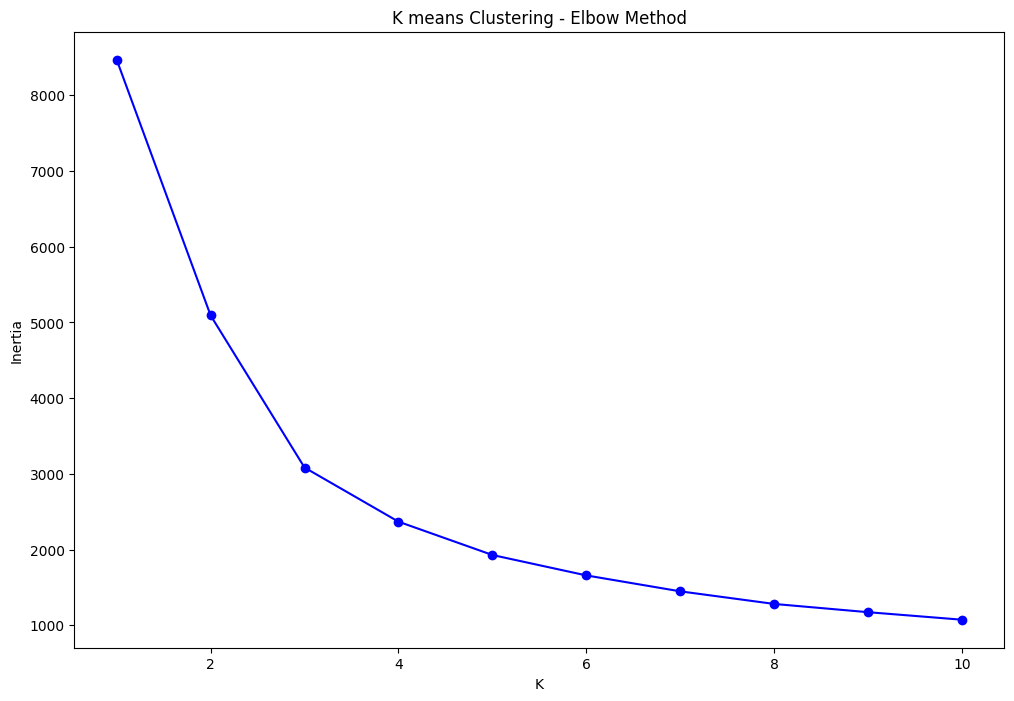

      QUANTITYORDERED  PRICEEACH    SALES  Clusters
0                  30      95.70  2871.00         2
1                  34      81.35  2765.90         2
2                  41      94.74  3884.34         1
3                  45      83.26  3746.70         0
4                  49     100.00  5205.27         1
...               ...        ...      ...       ...
2818               20     100.00  2244.40         2
2819               29     100.00  3978.51         2
2820               43     100.00  5417.57         1
2821               34      62.24  2116.16         3
2822               47      65.52  3079.44         0

[2823 rows x 4 columns]
          QUANTITYORDERED  PRICEEACH        SALES
Clusters                                         
0               43.897881  65.782813  2874.671407
1               43.793609  99.121212  5940.226631
2               27.779575  96.487391  3219.571355
3               28.228723  57.022571  1587.603050


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load dataset (encoding needed because the file has non-UTF-8 characters)
df = pd.read_csv(r"datasets/sales_data_sample.csv", encoding="unicode_escape")   # change to your file path

# Select only the numerical columns for clustering, then drop missing values
X = df[['QUANTITYORDERED', 'PRICEEACH', 'SALES']].dropna().copy()

# Scaling
sc = StandardScaler()
x_scaled = sc.fit_transform(X)

# Elbow method: inertia (sum of squared errors) for k = 1..10
inertia = []
K = range(1, 11)
for k in K:
    kmeans = KMeans(n_clusters=k, n_init=10, random_state=42)
    kmeans.fit(x_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(12, 8))
plt.plot(K, inertia, 'bo-')
plt.xlabel('K')
plt.ylabel('Inertia')
plt.title('K means Clustering - Elbow Method')
plt.show()

# Final model with the optimal k (read from the elbow plot)
optimal_k = 4
kmeans = KMeans(n_clusters=optimal_k, n_init=10, random_state=42)
X['Clusters'] = kmeans.fit_predict(x_scaled)
print(X)
print(X.groupby('Clusters').mean())   # average profile of each cluster